# Kuramoto–Sivashinsky (weakly chaotic regime)

$$
f_t = -\tfrac{1}{2}\,\|\nabla f\|^2 - \Delta f - \Delta^2 f
$$

## 1. Setup

In [1]:
import numpy as np

import nb_helpers as nb
from equivariant_pde_find.simulations import kuramoto_sivashinsky

EQ = "ks_wchaos"
NOISE = 0.02

# ── Best configurations from the hyperparameter sweep ───────────────
#
#   "eq"  = best of  multigraph / mod_multigraph
#   "neq" = best of  polyjet
#
# ────────────────────────────────────────────────────────────────────
BEST = {
    (0.00, "eq"): dict(
        library="multigraph", method="space_weak_direct", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=10.0,
    ),
    (0.00, "neq"): dict(
        library="polyjet", method="space_weak_direct", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=10.0,
    ),
    (0.02, "eq"): dict(
        library="mod_multigraph", method="space_weak_ibp", algorithm="mstls",
        backend="polynomial", m=12, alpha=0.25,
    ),
    (0.02, "neq"): dict(
        library="polyjet", method="space_weak_direct", algorithm="mstls",
        backend="polynomial", m=12, alpha=0.5,
    ),
}

## 2. Generate the data

In [2]:
SIM = dict(N=64, L=8 * np.pi, T_end=100.0, dt=0.1,
           save_every=5, seed=42)

clean, times = kuramoto_sivashinsky(**SIM, obs_noise=0.0)
noisy, _ = kuramoto_sivashinsky(**SIM, obs_noise=NOISE)

print(f'{len(clean)} snapshots over t ∈ [{times[0]:.2f}, {times[-1]:.2f}]'
      f' on a {clean.shape[1]}×{clean.shape[2]} grid')
print(f'f ∈ [{clean.min():.3f}, {clean.max():.3f}]')
nb.check_matches_dataset(clean, EQ, 'clean')
nb.check_matches_dataset(noisy, EQ, 'noise2pct')

201 snapshots over t ∈ [0.10, 100.10] on a 64×64 grid
f ∈ [-190.743, 1.844]
  vs data/ks_wchaos_clean.npz: max|Δ| = 0.00e+00  → identical
  vs data/ks_wchaos_noise2pct.npz: max|Δ| = 2.84e-14  → identical


2.842170943040401e-14

In [3]:
sigma = NOISE * clean.std()
fluct = clean - clean.mean(axis=(1, 2), keepdims=True)
print(f'global std           {clean.std():8.3f}   → noise σ = {sigma:.4f}')
print(f'fluctuation std      {fluct.std():8.3f}   → σ is {100 * sigma / fluct.std():.1f}% of the pattern')
print(f'late-time fluct std  {fluct[-1].std():8.3f}   → σ is {100 * sigma / fluct[-1].std():.1f}% of the pattern')

global std             60.762   → noise σ = 1.2152
fluctuation std         2.920   → σ is 41.6% of the pattern
late-time fluct std     3.382   → σ is 35.9% of the pattern


## 3. The motion

written: results/figures/ks_wchaos_motion.pdf
written: results/figures/ks_wchaos_motion.png


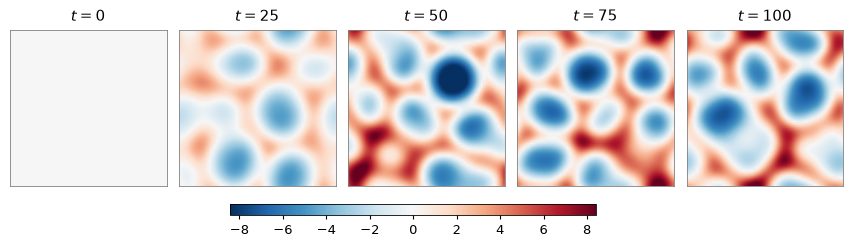

In [4]:
fig, paths = nb.plot_motion(
    clean, times, SIM['L'], n_frames=5,
    cmap='RdBu_r', symmetric=True, detrend=True,
    time_fmt='.0f',
    save_as=f'{EQ}_motion',
)
for p in paths:
    print('written:', p.split('/code/')[-1])

## 4. Design matrices

In [5]:
Lx = Ly = SIM['L']

data = {
    0.00: nb.regression_data(clean, times, EQ),
    NOISE: nb.regression_data(noisy, times, EQ),
}
print(f'{len(data[0.00][0])} interior snapshots')

ev = nb.JetEvaluator(clean, times, Lx, Ly, EQ)
ev.summary()

designs, fits = {}, {}
for key, cfg in BEST.items():
    f_snaps, ft_snaps, idx_sets, _ = data[key[0]]
    Theta, Ft, desc = nb.build_design(
        f_snaps, ft_snaps, idx_sets, Lx, Ly, cfg)
    designs[key] = (Theta, Ft, desc)
    fits[key] = nb.run_fit(Theta, Ft, cfg)
    print(f'{key[0] * 100:>3.0f}%  {key[1]:<4} {cfg["library"]:<15} '
          f'Theta {str(Theta.shape):<13} cond {np.linalg.cond(Theta):.2e}')

139 interior snapshots


Evaluation space: 119 jet monomials, 569,344 rows, 7 true active terms


  0%  eq   multigraph      Theta (13900, 20)   cond 3.40e+07


  0%  neq  polyjet         Theta (13900, 105)  cond 1.26e+08


  2%  eq   mod_multigraph  Theta (13900, 20)   cond 3.07e+07


  2%  neq  polyjet         Theta (13900, 105)  cond 9.75e+07


## 5. Recovery with clean data

In [6]:
print('Ground truth:  f_t = −0.5·‖∇f‖² − Δf − Δ²f')
print()
for group in ('eq', 'neq'):
    key = (0.00, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = −0.5·‖∇f‖² − Δf − Δ²f

── Multigraph ──
   Multigraph · weak (direct) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=10
   f_t = (-0.99773)Δf + (-0.49893)‖∇f‖² + (-0.99790)Δ²f
   3 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.002146   max|Δc| = 0.00421

── PolyJet ──
   PolyJet · weak (direct) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=10
   f_t = (-1.00050)f_xx + (-0.99491)f_yy + (-0.49939)f_x² + (-0.49847)f_y² + (-1.00066)f_xxxx + (-1.99238)f_xxyy + (-0.99625)f_yyyy
   7 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.002293   max|Δc| = 0.00762



In [7]:
for group in ('eq', 'neq'):
    key = (0.00, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Multigraph:
term       recovered        true       error
────────────────────────────────────────────
f_xxyy      -1.99579    -2.00000    4.21e-03
f_xx        -0.99773    -1.00000    2.27e-03
f_yy        -0.99773    -1.00000    2.27e-03
f_xxxx      -0.99790    -1.00000    2.10e-03
f_yyyy      -0.99790    -1.00000    2.10e-03
f_x²        -0.49893    -0.50000    1.07e-03
f_y²        -0.49893    -0.50000    1.07e-03

PolyJet:
term       recovered        true       error
────────────────────────────────────────────
f_xxyy      -1.99238    -2.00000    7.62e-03
f_xx        -1.00050    -1.00000   -5.05e-04
f_yy        -0.99491    -1.00000    5.09e-03
f_xxxx      -1.00066    -1.00000   -6.64e-04
f_yyyy      -0.99625    -1.00000    3.75e-03
f_x²        -0.49939    -0.50000    6.14e-04
f_y²        -0.49847    -0.50000    1.53e-03



## 6. Recovery at 2 % noise

In [8]:
print('Ground truth:  f_t = −0.5·‖∇f‖² − Δf − Δ²f')
print()
for group in ('eq', 'neq'):
    key = (NOISE, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = −0.5·‖∇f‖² − Δf − Δ²f



── Modified multigraph ──
   Modified multigraph · weak (IBP) · MSTLS · polynomial derivatives · m=12, p=6 · α=0.25
   f_t = (+1.01145)1 + (-0.68916)Δf + (-0.36236)‖∇f‖² + (-0.66853)Δ²f
   4 active terms · fp=1 fn=0 · not exact
   E_coeff = 0.6262   max|Δc| = 0.663

── PolyJet ──
   PolyJet · weak (direct) · MSTLS · polynomial derivatives · m=12, p=6 · α=0.5
   f_t = (-0.21036)1 + (-0.81230)f_xx + (-0.84343)f_yy + (-0.49659)f_x² + (-0.49229)f_y² + (-0.80598)f_xxxx + (-1.66388)f_xxyy + (-0.82506)f_yyyy + (+0.02015)f_xx² + (-0.08256)f_xy² + (+0.07570)f_yy·f_xx + (+0.01921)f_yy² + (-0.01468)f_x·f_xxx + (-0.10218)f_x·f_xyy + (-0.09671)f_y·f_xxy + (-0.01575)f_y·f_yyy
   16 active terms · fp=9 fn=0 · not exact
   E_coeff = 0.09623   max|Δc| = 0.336



In [9]:
for group in ('eq', 'neq'):
    key = (NOISE, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Modified multigraph:
term       recovered        true       error
────────────────────────────────────────────
f_xxyy      -1.33707    -2.00000    6.63e-01
f_xx        -0.68916    -1.00000    3.11e-01
f_yy        -0.68916    -1.00000    3.11e-01
f_xxxx      -0.66853    -1.00000    3.31e-01
f_yyyy      -0.66853    -1.00000    3.31e-01
f_x²        -0.36236    -0.50000    1.38e-01
f_y²        -0.36236    -0.50000    1.38e-01
1            1.01145     0.00000    1.01e+00  ← false positive

PolyJet:
term          recovered        true       error
───────────────────────────────────────────────
f_xxyy         -1.66388    -2.00000    3.36e-01
f_xx           -0.81230    -1.00000    1.88e-01
f_yy           -0.84343    -1.00000    1.57e-01
f_xxxx         -0.80598    -1.00000    1.94e-01
f_yyyy         -0.82506    -1.00000    1.75e-01
f_x²           -0.49659    -0.50000    3.41e-03
f_y²           -0.49229    -0.50000    7.71e-03
1              -0.21036     0.00000   -2.10e-01  ← false positive
f_x